In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RESULTS_FOLDER = Path("../../results/RF_group_results")
RESULTS_FOLDER.mkdir(parents=True, exist_ok=True)

ACTIVITIES = ["walking", "walking_upstairs", "walking_downstairs"]
LABEL_COLUMNS = ["split", "activity", "participant", "position", "platform", "recording_id"]

# Load the features made by build_features.py
data = pd.read_csv("../../data/processed/group/group_features.csv")
X = data.drop(columns=LABEL_COLUMNS)
y = data["activity"]

print(f"{len(data):,} windows x {X.shape[1]} features")
print(data.groupby(["participant", "activity"]).size().unstack(fill_value=0))

25,232 windows x 84 features
activity     walking  walking_downstairs  walking_upstairs
participant                                               
P01             9792                 713               847
P02             6399                 619               741
P03             4614                 620               887


In [4]:
def run_random_forest(is_test, name, file_name):
    # Train, test, print the results and returns the macro F1 and the model.
    X_train, X_test = X[~is_test], X[is_test]
    y_train, y_test = y[~is_test], y[is_test]

    # Train and predict (no scaling needed as class_weight handles the walking imbalance)
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    predictions = rf.predict(X_test)

    # Results
    macro_f1 = f1_score(y_test, predictions, average="macro")
    print(f"===== Random Forest: {name} =====")
    print(f"Train: {len(y_train):,} windows   Test: {len(y_test):,} windows")
    print(f"Accuracy: {accuracy_score(y_test, predictions):.3f}")
    print(f"Macro F1: {macro_f1:.3f}\n")
    print(classification_report(y_test, predictions, labels=ACTIVITIES, digits=3, zero_division=0))

    # Confusion matrix
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=ACTIVITIES, normalize="true", cmap="Blues", xticks_rotation=30)
    plt.title(f"Random Forest: {name}")
    plt.tight_layout()
    plt.savefig(RESULTS_FOLDER / f"RF_group_{file_name}_confusion_matrix.png", dpi=150)
    plt.show()

    # Scores per activity graph
    report = pd.DataFrame(classification_report(y_test, predictions, labels=ACTIVITIES, output_dict=True, zero_division=0)).T
    per_activity = report.loc[ACTIVITIES, ["precision", "recall", "f1-score"]]
    per_activity.plot(kind="bar", figsize=(7, 4), ylim=(0, 1), rot=0)
    plt.title(f"Random Forest: scores per activity ({name})")
    plt.ylabel("Score")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(RESULTS_FOLDER / f"RF_group_{file_name}_per_activity.png", dpi=150)
    plt.show()

    return macro_f1, rf

===== Random Forest: 70/30 by recording =====
Train: 17,131 windows   Test: 8,101 windows
Accuracy: 0.959
Macro F1: 0.883

                    precision    recall  f1-score   support

           walking      0.972     0.987     0.979      6935
  walking_upstairs      0.945     0.773     0.851       626
walking_downstairs      0.814     0.826     0.820       540

          accuracy                          0.959      8101
         macro avg      0.910     0.862     0.883      8101
      weighted avg      0.959     0.959     0.959      8101



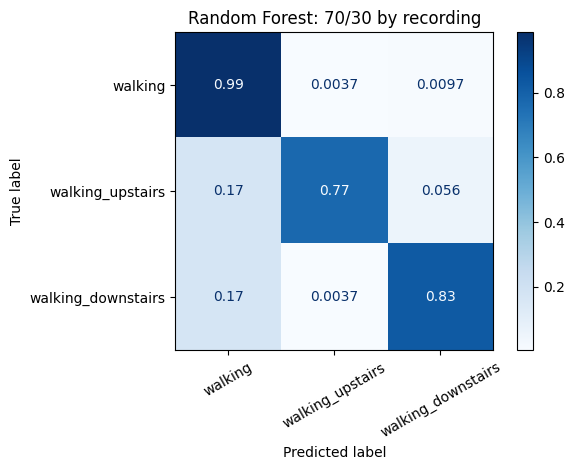

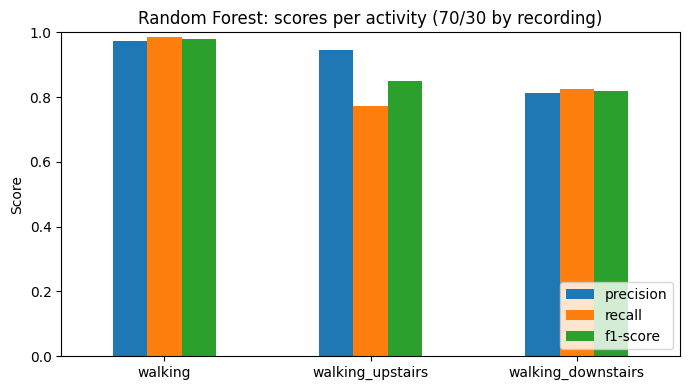

In [5]:
# 70/30 split by recording (read from the split column)
results = {}

is_test = data["split"] == "test"
results["70/30 by recording"], rf_70_30 = run_random_forest(is_test, "70/30 by recording", "70_30")

===== Random Forest: train on others, test on P01 (pocket) =====
Train: 13,880 windows   Test: 11,352 windows
Accuracy: 0.863
Macro F1: 0.309

                    precision    recall  f1-score   support

           walking      0.863     1.000     0.926      9792
  walking_upstairs      0.000     0.000     0.000       847
walking_downstairs      0.000     0.000     0.000       713

          accuracy                          0.863     11352
         macro avg      0.288     0.333     0.309     11352
      weighted avg      0.744     0.863     0.799     11352



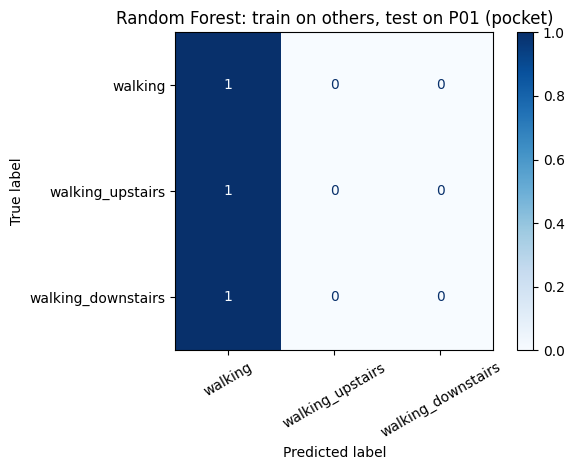

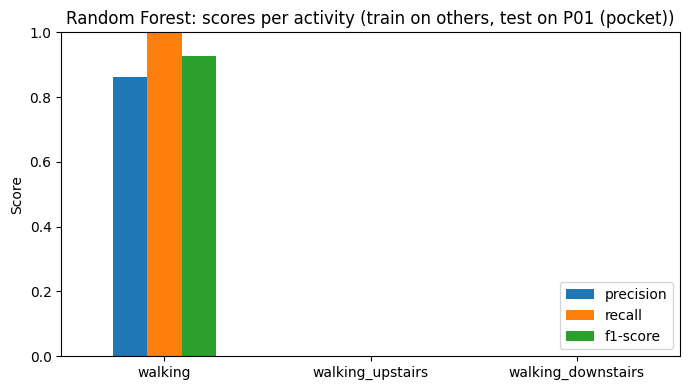

===== Random Forest: train on others, test on P02 (waist) =====
Train: 17,473 windows   Test: 7,759 windows
Accuracy: 0.796
Macro F1: 0.303

                    precision    recall  f1-score   support

           walking      0.821     0.964     0.886      6399
  walking_upstairs      0.312     0.007     0.013       741
walking_downstairs      0.018     0.006     0.009       619

          accuracy                          0.796      7759
         macro avg      0.384     0.326     0.303      7759
      weighted avg      0.708     0.796     0.733      7759



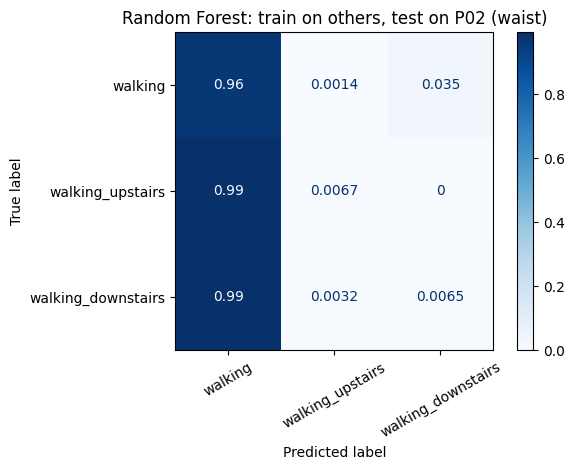

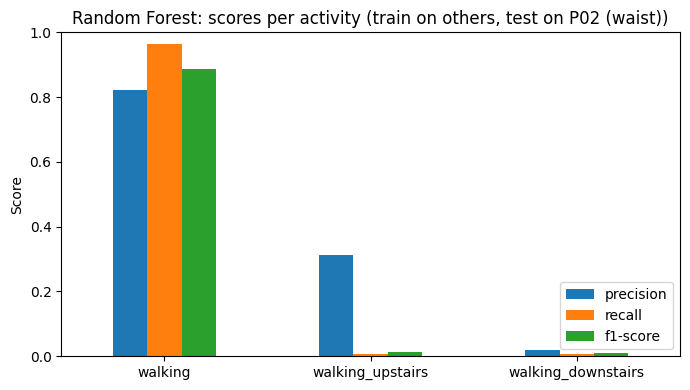

===== Random Forest: train on others, test on P03 (hand) =====
Train: 19,111 windows   Test: 6,121 windows
Accuracy: 0.753
Macro F1: 0.291

                    precision    recall  f1-score   support

           walking      0.761     0.998     0.864      4614
  walking_upstairs      0.060     0.005     0.008       887
walking_downstairs      0.000     0.000     0.000       620

          accuracy                          0.753      6121
         macro avg      0.274     0.334     0.291      6121
      weighted avg      0.582     0.753     0.652      6121



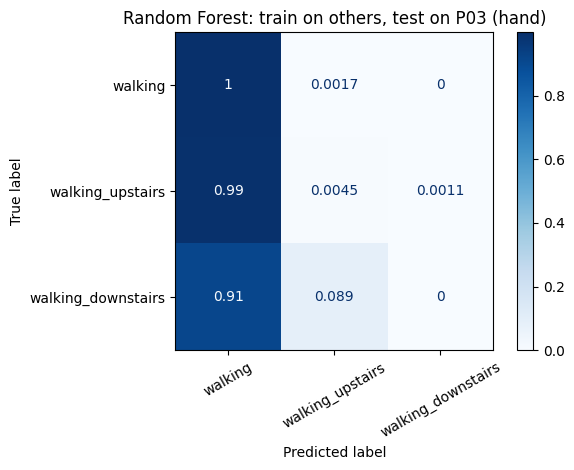

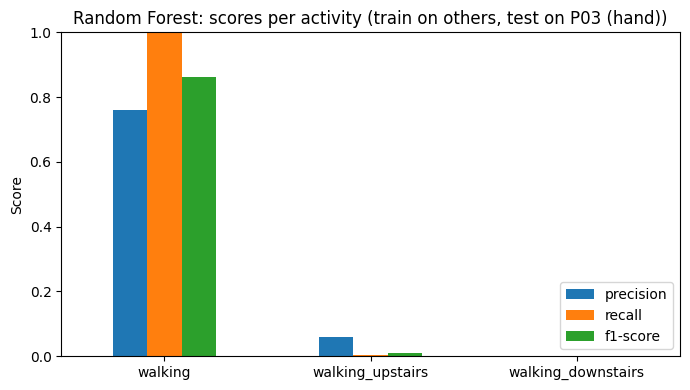

In [6]:
# Train on two people, test on the third (3 runs, alternating test person)
for person in sorted(data["participant"].unique()):
    is_test = data["participant"] == person
    position = data.loc[is_test, "position"].iloc[0]
    name = f"train on others, test on {person} ({position})"
    results[f"Test on {person} ({position})"], _ = run_random_forest(is_test, name, f"test_{person}")

In [7]:
# Summary of the 4 runs results
held_out_scores = [score for split, score in results.items() if split.startswith("Test on")]
results["Leave-one-participant-out average"] = sum(held_out_scores) / len(held_out_scores)

summary = pd.Series(results, name="Macro F1").round(3).to_frame()
summary.to_csv(RESULTS_FOLDER / "RF_group_summary.csv")
summary

,Macro F1
70/30 by recording,0.883
Test on P01 (pocket),0.309
Test on P02 (waist),0.303
Test on P03 (hand),0.291
Leave-one-participant-out average,0.301


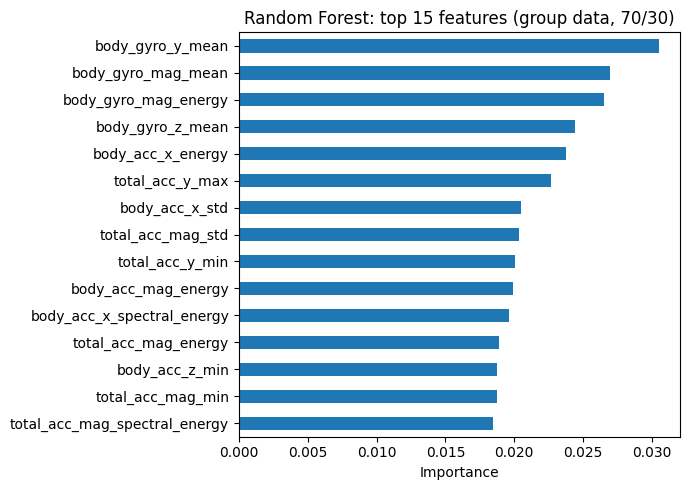

In [8]:
# Finds which feature was the most impactful in the RF
importance = pd.Series(rf_70_30.feature_importances_, index=X.columns).sort_values()

importance.tail(15).plot(kind="barh", figsize=(7, 5))
plt.title("Random Forest: top 15 features (group data, 70/30)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(RESULTS_FOLDER / "RF_group_feature_importance.png", dpi=150)
plt.show()